In [ ]:
import pandas as pd
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:

# Download latest version
path = kagglehub.dataset_download("theoverman/the-spotify-hit-predictor-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'the-spotify-hit-predictor-dataset' dataset.
Path to dataset files: /kaggle/input/the-spotify-hit-predictor-dataset


In [ ]:


df_10s = pd.read_csv("/kaggle/input/the-spotify-hit-predictor-dataset/dataset-of-10s.csv")
df_10s.head()

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1


In [ ]:
df_00s = pd.read_csv("/kaggle/input/the-spotify-hit-predictor-dataset/dataset-of-00s.csv")
df_00s.head()

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
0,Lucky Man,Montgomery Gentry,spotify:track:4GiXBCUF7H6YfNQsnBRIzl,0.578,0.471,4,-7.270,1,0.0289,0.368000,0.00000,0.159,0.532,133.061,196707,4,30.88059,13,1
1,On The Hotline,Pretty Ricky,spotify:track:1zyqZONW985Cs4osz9wlsu,0.704,0.854,10,-5.477,0,0.1830,0.018500,0.00000,0.148,0.688,92.988,242587,4,41.51106,10,1
2,Clouds Of Dementia,Candlemass,spotify:track:6cHZf7RbxXCKwEkgAZT4mY,0.162,0.836,9,-3.009,1,0.0473,0.000111,0.00457,0.174,0.300,86.964,338893,4,65.32887,13,0
3,"Heavy Metal, Raise Hell!",Zwartketterij,spotify:track:2IjBPp2vMeX7LggzRN3iSX,0.188,0.994,4,-3.745,1,0.1660,0.000007,0.07840,0.192,0.333,148.440,255667,4,58.59528,9,0
4,I Got A Feelin',Billy Currington,spotify:track:1tF370eYXUcWwkIvaq3IGz,0.630,0.764,2,-4.353,1,0.0275,0.363000,0.00000,0.125,0.631,112.098,193760,4,22.62384,10,1


In [ ]:
df_combined = pd.concat([df_10s, df_00s])
df_combined.head()

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1


In [ ]:
df_combined.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12270 entries, 0 to 5871
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track             12270 non-null  object 
 1   artist            12270 non-null  object 
 2   uri               12270 non-null  object 
 3   danceability      12270 non-null  float64
 4   energy            12270 non-null  float64
 5   key               12270 non-null  int64  
 6   loudness          12270 non-null  float64
 7   mode              12270 non-null  int64  
 8   speechiness       12270 non-null  float64
 9   acousticness      12270 non-null  float64
 10  instrumentalness  12270 non-null  float64
 11  liveness          12270 non-null  float64
 12  valence           12270 non-null  float64
 13  tempo             12270 non-null  float64
 14  duration_ms       12270 non-null  int64  
 15  time_signature    12270 non-null  int64  
 16  chorus_hit        12270 non-null  float64
 17 

In [ ]:
df_combined.describe()

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
count,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,12270.000000,1.227000e+04,12270.000000,12270.000000,12270.000000,12270.00000
mean,0.556088,0.680560,5.280114,-7.522540,0.645314,0.095310,0.215706,0.158413,0.196432,0.462172,121.999324,2.469773e+05,3.922820,40.887651,10.670823,0.50000
std,0.190986,0.239687,3.586004,5.172085,0.478438,0.096203,0.296671,0.310655,0.164153,0.250751,30.008028,1.151325e+05,0.390605,19.895327,4.841202,0.50002
min,0.058800,0.000251,0.000000,-47.327000,0.000000,0.022400,0.000000,0.000000,0.016700,0.000000,39.369000,1.592000e+04,0.000000,0.000000,1.000000,0.00000
25%,0.432000,0.548000,2.000000,-8.375000,0.000000,0.037325,0.006072,0.000000,0.095300,0.258000,97.699250,1.993870e+05,4.000000,27.824750,8.000000,0.00000
50%,0.573000,0.727000,5.000000,-6.069500,1.000000,0.055100,0.063200,0.000019,0.128000,0.455000,120.082500,2.288465e+05,4.000000,36.175345,10.000000,0.50000
75%,0.697000,0.871000,8.000000,-4.585000,1.000000,0.109000,0.312000,0.051150,0.257000,0.659000,141.316000,2.692170e+05,4.000000,48.157528,12.000000,1.00000
max,0.986000,0.999000,11.000000,1.137000,1.000000,0.956000,0.996000,0.998000,0.987000,0.982000,213.233000,4.170227e+06,5.000000,262.615400,169.000000,1.00000


In [ ]:
df_combined["target"].value_counts()

,count
target,
1,6135
0,6135


In [ ]:
df_combined.isnull().sum()

,0
track,0
artist,0
uri,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0


In [ ]:
df_combined.to_csv("/content/drive/MyDrive/szakdolgozat/hit-or-flop-dataset.csv")

In [ ]:
df = df_combined.drop(columns=["track", "artist", "uri"])

In [ ]:
X = df.drop(columns=["target"])
y = df["target"].astype(int)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.2),

    layers.Dense(32),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.1),

    layers.Dense(16),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.1),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 3,873 (15.13 KB)

 Non-trainable params: 224 (896.00 B)

In [ ]:
callback = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=16,
    callbacks=[callback]
)

Epoch 1/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.6512 - loss: 0.6404 - val_accuracy: 0.8050 - val_loss: 0.4241
Epoch 2/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7848 - loss: 0.4621 - val_accuracy: 0.8259 - val_loss: 0.4032
Epoch 3/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7831 - loss: 0.4634 - val_accuracy: 0.8243 - val_loss: 0.3948
Epoch 4/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7940 - loss: 0.4489 - val_accuracy: 0.8330 - val_loss: 0.3852
Epoch 5/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8017 - loss: 0.4331 - val_accuracy: 0.8310 - val_loss: 0.3886
Epoch 6/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7995 - loss: 0.4363 - val_accuracy: 0.8360 - val_loss: 0.3794
Epoch 7/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8063 - loss: 0.4312 - val_accuracy: 0.8355 - val_loss: 0.3835
Epoch 8/40
491/491 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8012 - loss: 0.4346 - val_accuracy: 0.

In [ ]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

Test accuracy: 0.8260


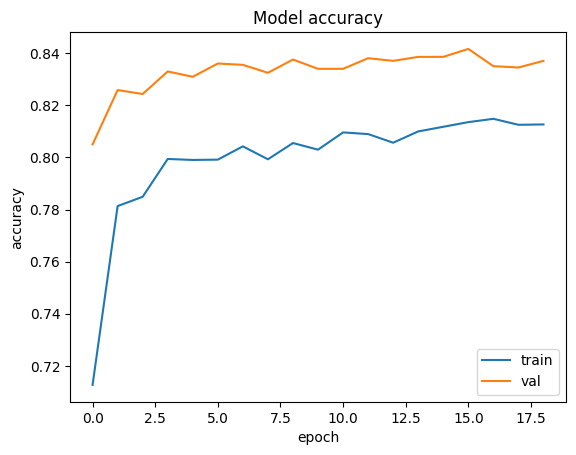

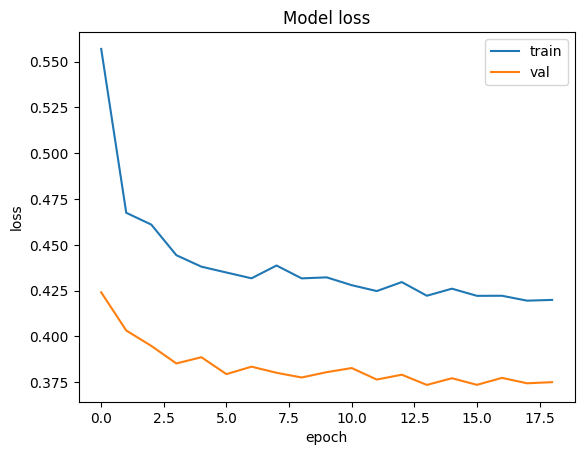

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'])
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
from sklearn.metrics import roc_auc_score, log_loss

y_pred_proba = model.predict(X_test_scaled)
auc = roc_auc_score(y_test, y_pred_proba)
loss = log_loss(y_test, y_pred_proba)
print("AUC:", auc)
print("Log loss:", loss)


77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
AUC: 0.9065746989928456
Log loss: 0.38326169698552626


In [ ]:
import joblib
model.save("hit_or_flop_classifier.keras")
joblib.dump(scaler, "scaler.pkl")

model.save("/content/drive/MyDrive/models/hit_or_flop_classifier.keras")
joblib.dump(scaler, "/content/drive/MyDrive/models/scaler.pkl")

['/content/drive/MyDrive/models/scaler.pkl']